# 📊 Retail Sales Analysis & Forecasting

### Sales Analytics | Exploratory Time-Series Regression

> Can recorded monthly sales help us understand product demand and assess simple prediction models?

This project analyzes retail and warehouse sales, compares product categories, and evaluates **Linear Regression** and **Decision Tree Regression** for predicting monthly retail sales volume from the **year and calendar month**.

**Business Context:** Inventory and purchasing teams need reliable demand estimates to plan stock and replenishment.

**Dataset:** [Warehouse and Retail Sales — Montgomery County, Maryland (Data.gov)](https://catalog.data.gov/dataset/warehouse-and-retail-sales)  
**Problem Type:** Regression | Exploratory Time-Series Prediction

> **Important:** Sales are measured in quantities (cases), **not monetary revenue**. The source is an alcoholic-beverage sales and movement dataset. Many calendar months are missing, so model results are exploratory rather than reliable operational forecasts.

## Business Problem

**Main question:** What can the available monthly sales records reveal about demand, and how do two simple regression models perform on later recorded months?

**Research questions**
- How do retail and warehouse sales change across recorded months?
- Which product categories account for the most retail volume?
- Are tentative calendar-month patterns visible?
- Which model has lower prediction error on the later observed months: Linear Regression or Decision Tree?

**Business decision:** Compare holdout **MAE** as a preliminary benchmark. Do not use these results as operational demand forecasts without more continuous monthly data and additional validation.

## Data Dictionary

| Column | Meaning |
|---|---|
| `YEAR`, `MONTH` | Observation year and calendar month |
| `ITEM TYPE` | Product category |
| `SUPPLIER` | Supplier name |
| `ITEM CODE`, `ITEM DESCRIPTION` | Product identifier and description |
| `RETAIL SALES` | Quantity of product sold at retail outlets (cases) |
| `WAREHOUSE SALES` | Warehouse sales volume (cases) |
| `RETAIL TRANSFERS` | Quantity transferred to retail outlets (cases) |

**Unit:** Quantities in cases, not dollars. The data concern Montgomery County alcoholic-beverage sales and movement

## Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

## Load Data

In [2]:
df = pd.read_csv('retail_sales.csv')

(df.head())

,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
0,2026,8,20705 IMPORTS,171162,PROSECCO 84 - 750ML,WINE,0.00,0.00,7.00
1,2026,8,20705 IMPORTS,180424,FENTO BICO DA RAN ALBARINO 750ML,WINE,0.00,0.00,1.00
2,2026,8,20705 IMPORTS,180363,CAN' LEANDRO LES FINQUES 750ML,WINE,0.00,0.00,1.00
3,2026,8,20705 IMPORTS,171163,BENNATI CASTELLANO PINOT GRIGIO 750ML,WINE,0.00,0.00,10.00
4,2026,8,AFARO LLC,246496,CONDE DE TRESAGUAS TEMPRANILLO - 750ML,WINE,0.00,0.00,1.00


## Exploratory Data Analysis

In [3]:
print('Rows, columns:', df.shape)

Rows, columns: (341037, 9)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 341037 entries, 0 to 341036
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   YEAR              341037 non-null  int64
 1   MONTH             341037 non-null  int64
 2   SUPPLIER          340833 non-null  str  
 3   ITEM CODE         341037 non-null  str  
 4   ITEM DESCRIPTION  341037 non-null  str  
 5   ITEM TYPE         341036 non-null  str  
 6   RETAIL SALES      341031 non-null  str  
 7   RETAIL TRANSFERS  341037 non-null  str  
 8   WAREHOUSE SALES   341037 non-null  str  
dtypes: int64(2), str(7)
memory usage: 48.0 MB


In [5]:
df.isnull().sum()

YEAR                  0
MONTH                 0
SUPPLIER            204
ITEM CODE             0
ITEM DESCRIPTION      0
ITEM TYPE             1
RETAIL SALES          6
RETAIL TRANSFERS      0
WAREHOUSE SALES       0
dtype: int64

## Data Quality & Preparation

> **Why:** A business analysis begins by checking missing values, numeric types, and quantity definitions. Negative quantities may reflect returns or adjustments; we retain them rather than silently removing them.

In [6]:
# Standardize Column Names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_', regex=False)

In [7]:
# Create a monthly date column
# Convert year and month into a date
df['date'] = pd.to_datetime(df[['year', 'month']].assign(day=1), errors='coerce')

df[['year', 'month', 'date']].head()

,year,month,date
0,2026,8,2026-08-01
1,2026,8,2026-08-01
2,2026,8,2026-08-01
3,2026,8,2026-08-01
4,2026,8,2026-08-01


In [8]:
# Convert Sales Columns to Numeric
cols = ['retail_sales', 'warehouse_sales', 'retail_transfers']

df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')

In [9]:
# Check numeric values after conversion (including newly introduced NaNs)
print(df[cols].isna().sum())

df[cols].describe().round(2)

retail_sales         166
warehouse_sales     2142
retail_transfers    1070
dtype: int64


,retail_sales,warehouse_sales,retail_transfers
count,340871.00,338895.00,339967.00
mean,6.79,14.36,6.80
std,27.17,62.26,27.23
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,0.25,1.00,0.00
75%,3.27,5.00,3.00
max,992.00,999.80,991.00


In [10]:
# Remove rows with missing dates or retail sales values
df = df.dropna(subset=['date', 'retail_sales']).copy()

In [11]:
# Handle Categorical Missing Values
df['item_type'] = df['item_type'].fillna('Unknown')

In [12]:
print('Date Range:', df['date'].min(), 'to', df['date'].max())

Date Range: 2017-06-01 00:00:00 to 2026-08-01 00:00:00


In [13]:
df = df.sort_values('date').reset_index(drop=True)

df.head()

,year,month,supplier,item_code,item_description,item_type,retail_sales,retail_transfers,warehouse_sales,date
0,2017,6,NaN,1279,EMPTY WINE KEG - KEGS,DUNNAGE,0.0,0.0,NaN,2017-06-01
1,2017,6,DOPS INC,409677,DRY CREEK S/BLC - 750ML,WINE,0.0,0.0,4.0,2017-06-01
2,2017,6,DOPS INC,25700,OLD SPECKLED HEN 1/2K,KEGS,0.0,0.0,1.0,2017-06-01
3,2017,6,DOPS INC,40958,WELLS BANANA BREAD - 11.2OZ CANS,BEER,0.0,0.0,1.0,2017-06-01
4,2017,6,DOPS INC,97026,GLUTENBERG BLONDE - 16.0Z CAN,BEER,0.0,0.0,6.0,2017-06-01


## Sales Performance Analysis

### Monthly Sales Trend

> **Why this chart?** This time-series line chart shows how sales change over time. It helps identify trends, drops, and unusual months to support inventory planning.

In [14]:
monthly = df.groupby('date')[['retail_sales', 'warehouse_sales']].sum().sort_index()

# Keep missing calendar months as missing values
monthly = monthly.asfreq('MS')

In [15]:
# Check how many months have sales data each year
monthly['retail_sales'].groupby(monthly.index.year).count()

date
2017     7
2018     2
2019    11
2020     4
2021     0
2022     0
2023     0
2024     0
2025     0
2026     3
Name: retail_sales, dtype: int64

In [16]:
# Check missing calendar months
print('Missing Months:', monthly['retail_sales'].isna().sum())

Missing Months: 84


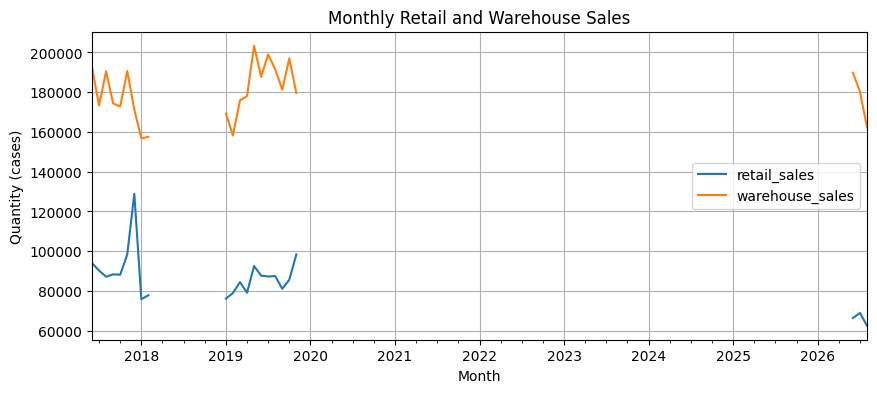

In [17]:
monthly.plot(title='Monthly Retail and Warehouse Sales',
             ylabel='Quantity (cases)')

plt.xlabel('Month')
plt.show()

**Data Quality Observation:** In this dataset, warehouse sales volumes are generally higher than retail sales volumes. There are **27 recorded months** and **84 missing calendar months** between June 2017 and August 2026. Missing months are **not** treated as zero sales. This severely limits forecasting reliability.

### Top Product Categories

> **Why this chart?** A ranked bar chart shows which product groups contribute most to retail volume. A commercial team can prioritize category-level planning

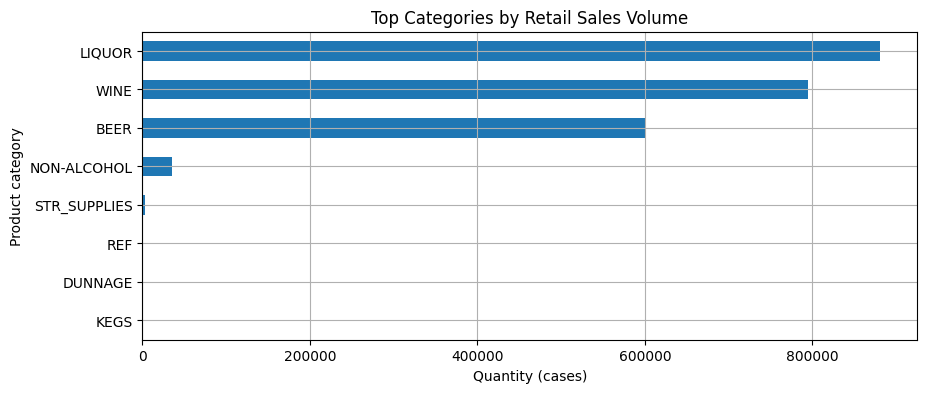

In [18]:
category_sales = df.groupby('item_type')['retail_sales'].sum().sort_values(ascending=False)
category_sales.head(8).sort_values().plot.barh(title='Top Categories by Retail Sales Volume')
plt.xlabel('Quantity (cases)')
plt.ylabel('Product category')
plt.show()

### Average Retail Volume by Calendar Month

> Average retail sales by calendar month help us understand seasonal patterns. However, the number of observations varies across months, so comparisons should be interpreted carefully

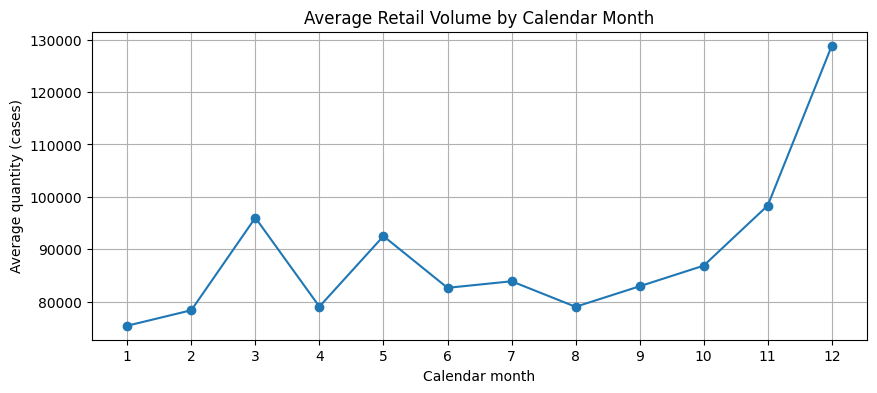

In [19]:
seasonality = monthly.groupby(monthly.index.month)['retail_sales'].mean()
seasonality.plot(marker='o', title='Average Retail Volume by Calendar Month')
plt.xticks(range(1, 13))
plt.xlabel('Calendar month')
plt.ylabel('Average quantity (cases)')
plt.show()

## Feature Engineering

**Target:** Monthly retail sales volume (cases)  
**Features:** Observation year and calendar month

We use all **27 months with recorded sales** and exclude missing calendar months without setting their sales to zero. The training and test data are kept in chronological order. No lagged sales features are used.

In [20]:
# Use all months with recorded retail sales
forecast = monthly.dropna(subset=['retail_sales']).copy()

forecast['year'] = forecast.index.year
forecast['month'] = forecast.index.month

print('Available Months:', len(forecast))

Available Months: 27


In [21]:
# Define features and target
x = forecast[['year', 'month']]
y = forecast['retail_sales']

**Train/Test Split**

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
# Keep chronological order to avoid using future data for training
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, shuffle=False
)

**Linear Regression**

> A simple, interpretable benchmark that predicts sales volume using the year and calendar month. No previous-month baseline is used because adjacent **recorded** months are not always adjacent calendar months.

In [24]:
lr = LinearRegression()
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-2336.17, 2016.07]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['year','month']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.79e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [25]:
lr_pred = lr.predict(x_test)

**Decision Tree Regression**

In [26]:
from sklearn.tree import DecisionTreeRegressor

In [27]:
dt = DecisionTreeRegressor(max_depth=3, random_state=42)
dt.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max

In [28]:
dt_pred = dt.predict(x_test)

### Model Evaluation

We compare both models on the **same later six recorded months** (21 training months; 6 test months). Because the test months are spread across 2020 and 2026, the metrics show performance on this small holdout—not reliable continuous monthly forecasting accuracy.

In [29]:
# Compare both models using MAE (lower is better)
mae = pd.Series({
    'Linear Regression': mean_absolute_error(y_test, lr_pred),
    'Decision Tree': mean_absolute_error(y_test, dt_pred)
})

print(mae.round(2))
print('Best Model by MAE:', mae.idxmin())

Linear Regression     9943.35
Decision Tree        17029.96
dtype: float64
Best Model by MAE: Linear Regression


In [30]:
# Compare additional regression metrics for both models
from sklearn.metrics import r2_score

metrics = pd.DataFrame({
    'RMSE': [mean_squared_error(y_test, lr_pred)**0.5,
             mean_squared_error(y_test, dt_pred)**0.5],
    'R2': [r2_score(y_test, lr_pred),
           r2_score(y_test, dt_pred)]
}, index=['Linear Regression', 'Decision Tree'])

metrics.round(2)

,RMSE,R2
Linear Regression,13969.47,0.20
Decision Tree,19342.91,-0.54


> **Why this chart?** MAE measures average prediction error in cases. A lower bar means a smaller average error **on the six observed test months**.

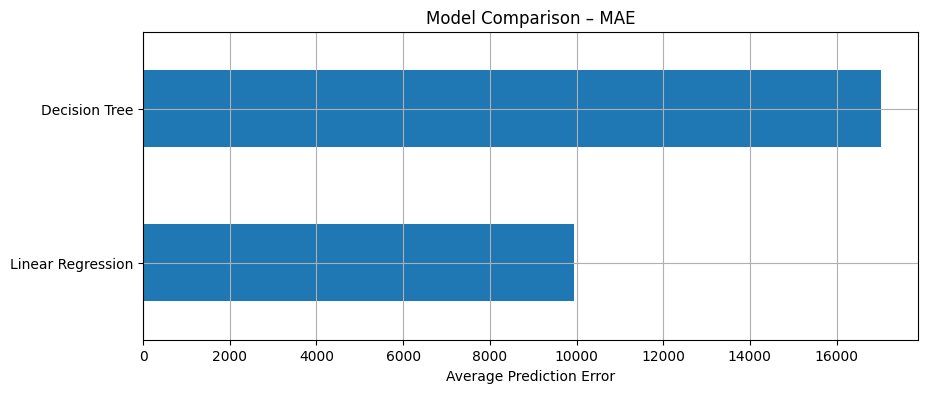

In [31]:
mae.sort_values().plot.barh(title='Model Comparison – MAE')
plt.xlabel('Average Prediction Error')
plt.show()

### Actual vs. Predicted Sales

> The grouped bar chart compares actual sales with predictions from Linear Regression and Decision Tree. The six test observations come from 2020 and 2026, not six consecutive months

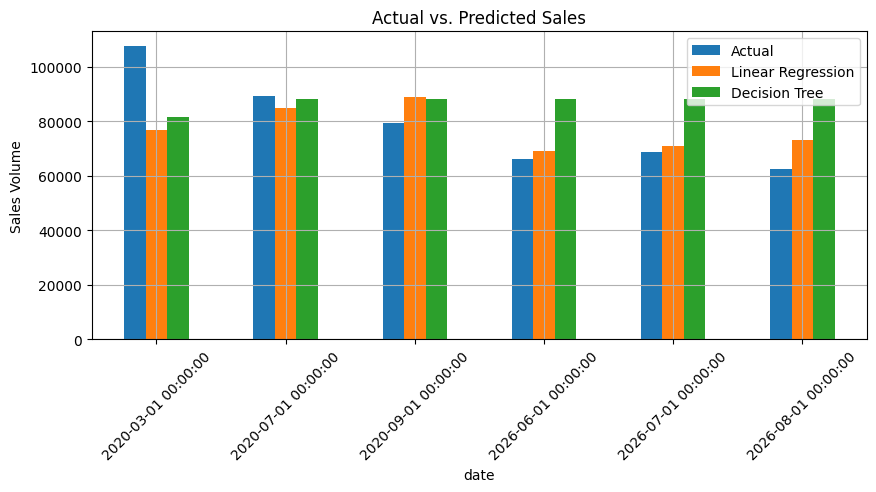

In [32]:
# Compare actual sales with both model predictions
comparison = pd.DataFrame({
    'Actual': y_test,
    'Linear Regression': lr_pred,
    'Decision Tree': dt_pred
}, index=y_test.index)

comparison.plot.bar(title='Actual vs. Predicted Sales')
plt.ylabel('Sales Volume')
plt.xticks(rotation=45)
plt.show()

## Model Evaluation Summary

**Business Interpretation:** In this notebook snapshot, **Linear Regression** has the lower holdout MAE (**9,943.35 cases**) compared with Decision Tree (**17,029.96 cases**). This comparison is based on only six recorded test months, including a large gap between 2020 and 2026. It is a preliminary model comparison, **not evidence of reliable future forecasts**.

In [33]:
# Summarize the business findings
print('Highest-volume category:', category_sales.index[0])
print('Months used for modeling:', len(y))
print('Test months:', ', '.join(y_test.index.strftime('%Y-%m')))
print('Best model by MAE:', mae.idxmin())
print('Lowest MAE:', round(mae.min(), 2))

Highest-volume category: LIQUOR
Months used for modeling: 27
Test months: 2020-03, 2020-07, 2020-09, 2026-06, 2026-07, 2026-08
Best model by MAE: Linear Regression
Lowest MAE: 9943.35


## Results and Conclusion

This project explored retail and warehouse sales, ranked product categories, and examined average sales by calendar month. The highest-volume retail category in the provided dataset is **LIQUOR**.

We trained **Linear Regression** and **Decision Tree Regression** using only **year and month** as predictors. Both models were evaluated chronologically on six later observed months. **Linear Regression performed better on this holdout**, with an MAE of **9,943.35 cases**, compared with **17,029.96 cases** for Decision Tree. These results describe this particular small test set only.

**Limitations**

- **Incomplete monthly history:** Only **27 months** contain recorded sales, while **84 calendar months** are missing; no records are available for 2021–2025. Missing records do not mean zero demand.
- **Small, discontinuous test set:** The six test observations span 2020 and 2026, making model evaluation unstable.
- **Limited predictors:** The models use **year and month only**—not past sales, prices, promotions, holidays, or inventory availability.
- **Model limitations:** Linear Regression extrapolates a simple time relationship; Decision Trees generally cannot extrapolate beyond the year values seen during training.
- **Data validation:** Returns, corrections, and nonnumeric values in source columns require business interpretation.

**Conclusion:** The notebook demonstrates a transparent business analytics workflow and an initial model comparison. More complete, continuous monthly records and additional predictors would be required before using forecasts for inventory or purchasing decisions.